# Remix Metaheuristic FS + HPO Imbalance-Aware — V2.1 (Patch Audit, CPU 12 Worker)

**Tugas FP Kecerdasan Komputasional A — Kelompok KK A 02**
Burhanudin Yusuf Abdullah Ar Ramadhan (6025261048), Renaldy Junedy (6025261035),
Adnan Fauzan Ramdhani (6025261004), Muhammad Saifullah Irfanuddin (6025261056)

Notebook ini = **V2 + patch v2.1** (`patch_v2_1_revisi_pipeline_audit_fixes.md`).

## 5 temuan audit yang diperbaiki

1. **E1A memilih strategi berdasarkan `best_fit` ($F_{AP+BA}$)**, bukan `val_ap`,
   dengan tie-breaker metode lebih sederhana (`none → classweight → under →
   smote → borderline`). Framingham cat/xgb tidak lagi memilih `none`.
2. **E2A benar-benar memakai SMOTE in-fold** (`imb_method="smote"`) sehingga
   `FS→SMOTE` dan `SMOTE→FS` menghasilkan metrik berbeda; seluruh CSV
   dideduplikasi dengan kunci unik per tahap.
3. **Holm-Bonferroni per keluarga hipotesis** (`family` × `metric`), bukan satu
   keluarga global; Friedman mencakup 5 metrik untuk E1A/E2B/E3B.
4. **XAI SVM Cleveland** diperbaiki (`probability=True` + wrapper sigmoid) dan
   std E3C dihitung *within-dataset* antar-seed.
5. **Profil `fast` diselaraskan**: E1A 5 seed, E2t 4 transfer termasuk `step`,
   E4 3 arsitektur termasuk `joint_full_imb`.

## Verifikasi

Test **T1–T10** dijalankan otomatis; notebook berhenti jika ada yang FAIL.
Konfigurasi CPU: `MFL_USE_GPU=0`, `MFL_WORKERS=12`, `MFL_THREADS=1`.

| Profil | Isi |
|---|---|
| `smoke` | subset + T1–T10 (~20–30 menit CPU) |
| `fast` | ringkas, sudah mencakup 5 seed E1A, 4 transfer, 3 arsitektur |
| `full` | 2.526 sel protokol lengkap |



In [1]:
# ============================================================================
# 1. Konfigurasi CPU 12 worker (sesuai instruksi)
# ============================================================================
import os
import sys
import json
import time
import warnings
from pathlib import Path

# WAJIB: konfigurasi CPU yang diminta.  Jangan diubah di dalam notebook.
os.environ["MFL_USE_GPU"] = "0"
os.environ.setdefault("MFL_WORKERS", "12")
os.environ.setdefault("MFL_THREADS", "1")
for _v in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS",
           "VECLIB_MAXIMUM_THREADS", "NUMEXPR_NUM_THREADS"]:
    os.environ[_v] = "1"

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

try:
    from IPython.display import display, Image, Markdown
except Exception:
    Image = None
    def display(*objs, **kwargs):
        for obj in objs:
            print(obj)
    def Markdown(x):
        return x

warnings.filterwarnings("ignore")
pd.set_option("display.width", 240)
pd.set_option("display.max_columns", 60)

_CWD = Path.cwd().resolve()
PROJECT_ROOT = _CWD.parent if _CWD.name.lower() == "replication" else _CWD
REPO = PROJECT_ROOT / "replication"
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
os.environ["PYTHONPATH"] = str(REPO) + os.pathsep + os.environ.get("PYTHONPATH", "")

PROFILE = os.environ.get("MFL_RJ_PROFILE", "fast").strip().lower()
if PROFILE not in {"smoke", "fast", "full"}:
    PROFILE = "fast"
WORKERS = int(os.environ.get("MFL_WORKERS", "12"))
print("=" * 78)
print("REMIX FS+HPO IMBALANCE-AWARE — V2 (REVISI PROTOKOL) — CPU MODE")
print("=" * 78)
print(f"Profil   : {PROFILE} | Worker: {WORKERS} | Threads: 1 | GPU: OFF")
print(f"Root     : {PROJECT_ROOT}")
print("=" * 78)


REMIX FS+HPO IMBALANCE-AWARE — V2 (REVISI PROTOKOL) — CPU MODE
Profil   : fast | Worker: 12 | Threads: 1 | GPU: OFF
Root     : D:\Plus Iso\Kuliah S2\Kecerdasan Komputasional A\Percobaan Final KK


In [2]:
# ============================================================================
# 2. Requirement check — paket, 6 dataset, mode CPU
# ============================================================================
import importlib
rows = []
for name, crit in [("sklearn", True), ("imblearn", True), ("xgboost", True),
                   ("catboost", True), ("shap", True), ("lime", True),
                   ("scipy", True), ("tabulate", True), ("kagglehub", False),
                   ("torch", False)]:
    try:
        mod = importlib.import_module(name)
        rows.append({"paket": name, "status": "OK",
                     "versi": str(getattr(mod, "__version__", "?"))})
    except Exception as exc:
        rows.append({"paket": name, "status": f"HILANG ({exc})", "versi": "-"})
display(pd.DataFrame(rows))
if any(r["status"].startswith("HILANG") for r in rows if r["paket"] in
       {"sklearn", "imblearn", "xgboost", "catboost", "shap", "lime", "scipy", "tabulate"}):
    raise RuntimeError("Paket kritis hilang; instal dulu.")

import rj2_core as core
import run_rj_v2 as runner
import remix_core as rc
# Konfigurasi CPU dipaksa: XGB/CatBoost tidak memakai CUDA.
rc.configure_gpu(False)
print("[cpu] configure_gpu(False):", rc.USE_GPU, rc.XGB_KWARGS, rc.CAT_KWARGS)
print(f"[profile] {PROFILE} | datasets={len(core.DATASETS6)} "
      f"| full protocol 2.526 sel")


,paket,status,versi
0,sklearn,OK,1.9.1
1,imblearn,OK,0.14.2
2,xgboost,OK,3.2.0
3,catboost,OK,1.2.10
4,shap,OK,0.51.0
5,lime,OK,?
6,scipy,OK,1.17.1
7,tabulate,OK,0.10.0
8,kagglehub,OK,1.0.2
9,torch,OK,2.14.0+cu126


[cpu] configure_gpu(False): False {} {}
[profile] fast | datasets=6 | full protocol 2.526 sel


In [3]:
# ============================================================================
# 3. Cache 6 dataset (70/15/15, preprocessing fit pada train saja)
# ============================================================================
t0 = time.perf_counter()
INFO6 = core.prepare_v2()
print(f"\n[cache] selesai {time.perf_counter()-t0:.1f}s")
AUD = pd.DataFrame([
    {"dataset": k, "rows": v["rows_used"], "fitur": v["d_features"],
     "positif_%": round(v["class_pos_frac"] * 100, 2),
     "train": v["n_train"], "val": v["n_val"], "test": v["n_test"],
     "preproc_fit_rows": v.get("preproc_fit_rows")}
    for k, v in INFO6.items()])
display(AUD)
print("\nBRFSS = stratified subsample 5.000 baris (8,1% positif), dataset ke-6 "
      "untuk menguji imbalance ekstrem di luar Framingham.")



[cache] selesai 0.1s


,dataset,rows,fitur,positif_%,train,val,test,preproc_fit_rows
0,cleveland,303,13,45.87,212,45,46,212
1,statlog,270,13,44.44,189,40,41,189
2,framingham,4240,15,15.19,2968,636,636,2968
3,cardio,4240,11,50.85,2968,636,636,2968
4,hungarian,293,13,36.18,205,44,44,205
5,brfss,5000,18,8.08,3500,750,750,3500



BRFSS = stratified subsample 5.000 baris (8,1% positif), dataset ke-6 untuk menguji imbalance ekstrem di luar Framingham.


## Verifikasi otomatis (Definition of Done)

Enam assertion wajib dijalankan sebelum eksperimen penuh. Jika salah satu gagal,
notebook berhenti (`assert`) agar tidak menghasilkan klaim yang tidak valid.


In [4]:
# ============================================================================
# 4. Definition of Done — 6 assertion (Test 1-4 dijalankan di sini)
# ============================================================================
ASSERT = []
def _check(name, ok, detail):
    ASSERT.append({"test": name, "status": "PASS" if ok else "FAIL",
                   "detail": str(detail)})
    print(("PASS " if ok else "FAIL ") + name + " :: " + str(detail))

# ---- Test 1: undersampling benar-benar aktif pada Framingham
r_none = core.run_e1a_cell("framingham", "rf", "none", seed=42)
r_under = core.run_e1a_cell("framingham", "rf", "under", seed=42)
_check("T1 undersampling aktif",
       (r_under["train_neg_after"] < r_none["train_neg_after"])
       and (r_under["best_fit"] != 9.0)
       and (abs(r_under["test_average_precision"] - r_none["test_average_precision"]) > 1e-9),
       f"neg {r_none['train_neg_after']} -> {r_under['train_neg_after']}, "
       f"AP {r_none['test_average_precision']:.4f} vs {r_under['test_average_precision']:.4f}")

# ---- Test 2: class-weight adaptif
r_cw_f = core.run_e1a_cell("framingham", "rf", "classweight", seed=42)
r_cw_c = core.run_e1a_cell("cardio", "rf", "classweight", seed=42)
_check("T2a class-weight cardio ~1",
       0.90 <= r_cw_c["class_weight_pos"] <= 1.10, r_cw_c["class_weight_pos"])
_check("T2b class-weight framingham ~5.58",
       abs(r_cw_f["class_weight_pos"] - 5.58) < 0.15, r_cw_f["class_weight_pos"])

# ---- Test 3: budget parity ketat
b_fs = core.run_cell("T3", "framingham", "rf", fs_opt="bmao", method="smote",
                     architecture="fs_only", seed=42, budget=80)
b_hpo = core.run_cell("T3", "framingham", "rf", fs_opt="none", method="smote",
                      architecture="hpo_only", seed=42, budget=160)
b_joint = core.run_cell("T3", "framingham", "rf", fs_opt="bmao", method="smote",
                        architecture="joint_fixed_imb", seed=42, budget=160)
b_tandem = core.run_cell("T3", "framingham", "rf", fs_opt="bmao", method="smote",
                         architecture="tandem", seed=42, budget=160)
_check("T3a FS-only n_evals=80", b_fs["n_evals"] == 80, b_fs["n_evals"])
_check("T3b HPO-only n_evals=160", b_hpo["n_evals"] == 160, b_hpo["n_evals"])
_check("T3c Joint n_evals=160", b_joint["n_evals"] == 160, b_joint["n_evals"])
_check("T3d Tandem n_evals=160", b_tandem["n_evals"] == 160, b_tandem["n_evals"])

# ---- Test 4: zero leakage (resampler & preprocessing)
LG = core.leakage_guard_test("framingham", "rf")
_check("T4a resampler in-fold only", LG["pass_resampler_infold"], LG["resampler_rows_seen"])
_check("T4b preprocessing fit train-only", LG["pass_preproc_train_only"],
       f"fit_rows={LG['preproc_fit_rows']} n_train={LG['n_train']}")

ASSERT_DF = pd.DataFrame(ASSERT)
display(ASSERT_DF)
if (ASSERT_DF["status"] == "FAIL").any():
    raise AssertionError("Definition of Done GAGAL — lihat tabel di atas.")
print("\nSemua assertion Test 1-4 PASS.")


PASS T1 undersampling aktif :: neg 2517 -> 563, AP 0.3162 vs 0.2930
PASS T2a class-weight cardio ~1 :: 0.9668654738237243
PASS T2b class-weight framingham ~5.58 :: 5.580931263858093
PASS T3a FS-only n_evals=80 :: 80
PASS T3b HPO-only n_evals=160 :: 160
PASS T3c Joint n_evals=160 :: 160
PASS T3d Tandem n_evals=160 :: 160
PASS T4a resampler in-fold only :: [1666, 1667]
PASS T4b preprocessing fit train-only :: fit_rows=2968 n_train=2968


,test,status,detail
0,T1 undersampling aktif,PASS,"neg 2517 -> 563, AP 0.3162 vs 0.2930"
1,T2a class-weight cardio ~1,PASS,0.9668654738237243
2,T2b class-weight framingham ~5.58,PASS,5.580931263858093
3,T3a FS-only n_evals=80,PASS,80
4,T3b HPO-only n_evals=160,PASS,160
5,T3c Joint n_evals=160,PASS,160
6,T3d Tandem n_evals=160,PASS,160
7,T4a resampler in-fold only,PASS,"[1666, 1667]"
8,T4b preprocessing fit train-only,PASS,fit_rows=2968 n_train=2968



Semua assertion Test 1-4 PASS.


## E1A — 5 metode imbalance × 6 klasifier × 6 dataset × 5 seed (900 sel)

Seleksi strategi adaptif per (dataset, klasifier) memakai rata-rata inner-CV
`F_AP+BA`; test set tidak tersentuh. Output:
`rj2_exp1a_imbalance.csv`, `rj2_strategy_selection.csv`.


In [5]:
# ============================================================================
# 5. E1A — imbalance screening (Tujuan 01)
# ============================================================================
E1A = runner.stage_e1a()
if E1A is not None and len(E1A):
    piv = E1A.pivot_table(index="imb_method",
                          columns="dataset",
                          values="test_recall", aggfunc="mean").round(3)
    print("Test Recall per metode x dataset:")
    display(piv)
    SEL = pd.read_csv(Path(core.RES2) / "rj2_strategy_selection.csv")
    print("\nStrategi terpilih (30 baris):")
    display(SEL.head(30))


[rj2_exp1a_imbalance.csv] 900 tasks, 900 to run, 300 cached
[rj2_exp1a_imbalance.csv] 20/900 (11s)
[rj2_exp1a_imbalance.csv] 40/900 (11s)
[rj2_exp1a_imbalance.csv] 60/900 (12s)
[rj2_exp1a_imbalance.csv] 80/900 (14s)
[rj2_exp1a_imbalance.csv] 100/900 (15s)
[rj2_exp1a_imbalance.csv] 120/900 (16s)
[rj2_exp1a_imbalance.csv] 140/900 (22s)
[rj2_exp1a_imbalance.csv] 160/900 (22s)
[rj2_exp1a_imbalance.csv] 180/900 (22s)
[rj2_exp1a_imbalance.csv] 200/900 (23s)
[rj2_exp1a_imbalance.csv] 220/900 (25s)
[rj2_exp1a_imbalance.csv] 240/900 (25s)
[rj2_exp1a_imbalance.csv] 260/900 (26s)
[rj2_exp1a_imbalance.csv] 280/900 (29s)
[rj2_exp1a_imbalance.csv] 300/900 (34s)
[rj2_exp1a_imbalance.csv] 320/900 (49s)
[rj2_exp1a_imbalance.csv] 340/900 (53s)
[rj2_exp1a_imbalance.csv] 360/900 (66s)
[rj2_exp1a_imbalance.csv] 380/900 (73s)
[rj2_exp1a_imbalance.csv] 400/900 (74s)
[rj2_exp1a_imbalance.csv] 420/900 (76s)
[rj2_exp1a_imbalance.csv] 440/900 (95s)
[rj2_exp1a_imbalance.csv] 460/900 (103s)
[rj2_exp1a_imbalance.cs

dataset,brfss,cardio,cleveland,framingham,hungarian,statlog
imb_method,,,,,,
borderline,0.412,0.705,0.898,0.354,0.840,0.859
classweight,0.689,0.698,0.900,0.531,0.883,0.865
none,0.041,0.705,0.898,0.060,0.788,0.859
smote,0.402,0.705,0.898,0.351,0.804,0.859
under,0.743,0.704,0.903,0.489,0.831,0.859



Strategi terpilih (30 baris):


,dataset,classifier,imb_method,mean_fit,val_ap,val_ba,test_average_precision,test_balanced_accuracy,test_recall
0,brfss,cat,classweight,0.560308,0.271205,0.726322,0.334211,0.785797,0.780000
1,brfss,knn,under,0.662793,0.144100,0.644881,0.178726,0.681159,0.673333
2,brfss,rf,under,0.584908,0.239969,0.707773,0.275546,0.756884,0.756667
3,brfss,stack,classweight,0.555019,0.270064,0.741115,0.319089,0.761667,0.816667
4,brfss,svm,classweight,0.572475,0.266152,0.702852,0.300142,0.765580,0.816667
5,brfss,xgb,under,0.584610,0.240545,0.707725,0.260645,0.729130,0.706667
6,cardio,cat,under,0.270653,0.789645,0.737605,0.785995,0.741341,0.712074
7,cardio,knn,under,0.345896,0.693984,0.681031,0.702305,0.701332,0.696594
8,cardio,rf,under,0.275287,0.784599,0.732958,0.761139,0.736048,0.703406
9,cardio,stack,under,0.273812,0.785644,0.735208,0.775674,0.736697,0.702786


## E1B — Audit kebocoran SMOTE pra-split vs in-fold (180 sel)

Tiga dataset timpang × 6 klasifier × 2 protokol × 5 seed. Membuktikan inflasi
performa palsu jika SMOTE dilakukan sebelum split.


In [6]:
# ============================================================================
# 6. E1B — leakage audit
# ============================================================================
E1B = runner.stage_e1b()
if E1B is not None and len(E1B):
    g = E1B.groupby("protocol")[["test_average_precision", "test_recall",
                                 "test_balanced_accuracy"]].mean().round(4)
    display(g)
    if {"smote_presplit_leakage", "smote_infold_clean"}.issubset(g.index):
        d = (g.loc["smote_presplit_leakage"] - g.loc["smote_infold_clean"])
        print(f"\nInflasi palsu: AP {d['test_average_precision']:+.4f}, "
              f"Recall {d['test_recall']:+.4f}, BA {d['test_balanced_accuracy']:+.4f}")


[rj2_exp1b_leakage_audit.csv] 180 tasks, 180 to run, 8 cached
[rj2_exp1b_leakage_audit.csv] 20/180 (61s)
[rj2_exp1b_leakage_audit.csv] 40/180 (63s)
[rj2_exp1b_leakage_audit.csv] 60/180 (64s)
[rj2_exp1b_leakage_audit.csv] 80/180 (68s)
[rj2_exp1b_leakage_audit.csv] 100/180 (72s)
[rj2_exp1b_leakage_audit.csv] 120/180 (79s)
[rj2_exp1b_leakage_audit.csv] 140/180 (81s)
[rj2_exp1b_leakage_audit.csv] 160/180 (83s)
[rj2_exp1b_leakage_audit.csv] 180/180 (134s)
[rj2_exp1b_leakage_audit.csv] wrote 180 rows -> D:\Plus Iso\Kuliah S2\Kecerdasan Komputasional A\Percobaan Final KK\replication\results_rj_v2\rj2_exp1b_leakage_audit.csv


,test_average_precision,test_recall,test_balanced_accuracy
protocol,,,
smote_infold_clean,0.4338,0.5342,0.6809
smote_presplit_leakage,0.9238,0.8099,0.8518



Inflasi palsu: AP +0.4900, Recall +0.2757, BA +0.1709


## E2A — Sensitivitas fitness & urutan resampling (216 sel)

`F_Acc`, `F_BA`, `F_AP+BA` (FS→SMOTE) dan `SMOTE→FS` pada 3 dataset timpang ×
3 klasifier × 2 optimizer × 3 seed. Fokus: **Recall** dan **BA**.


In [7]:
# ============================================================================
# 7. E2A — fitness & order ablation (Tujuan 02)
# ============================================================================
E2A = runner.stage_e2a()
if E2A is not None and len(E2A):
    g = E2A.groupby("variant")[["test_recall", "test_balanced_accuracy",
                                "test_average_precision"]].mean().round(4)
    display(g)


[rj2_exp2a_fitness_order.csv] 216 tasks, 216 to run, 24 cached
[rj2_exp2a_fitness_order.csv] 20/216 (389s)
[rj2_exp2a_fitness_order.csv] 40/216 (673s)
[rj2_exp2a_fitness_order.csv] 60/216 (801s)
[rj2_exp2a_fitness_order.csv] 80/216 (973s)
[rj2_exp2a_fitness_order.csv] 100/216 (1040s)
[rj2_exp2a_fitness_order.csv] 120/216 (1131s)
[rj2_exp2a_fitness_order.csv] 140/216 (1247s)
[rj2_exp2a_fitness_order.csv] 160/216 (1589s)
[rj2_exp2a_fitness_order.csv] 180/216 (1724s)
[rj2_exp2a_fitness_order.csv] 200/216 (2078s)
[rj2_exp2a_fitness_order.csv] 216/216 (2293s)
[rj2_exp2a_fitness_order.csv] wrote 216 rows -> D:\Plus Iso\Kuliah S2\Kecerdasan Komputasional A\Percobaan Final KK\replication\results_rj_v2\rj2_exp2a_fitness_order.csv


,test_recall,test_balanced_accuracy,test_average_precision
variant,,,
bba|acc|fs_then_smote,0.4918,0.6890,0.4685
bba|ap_ba|fs_then_smote,0.5262,0.6970,0.4842
bba|ap_ba|smote_then_fs,0.5269,0.7002,0.4800
bba|ba|fs_then_smote,0.5135,0.6904,0.4732
bmao|acc|fs_then_smote,0.4121,0.6546,0.4263
bmao|ap_ba|fs_then_smote,0.5270,0.6973,0.4841
bmao|ap_ba|smote_then_fs,0.5128,0.6864,0.4756
bmao|ba|fs_then_smote,0.5202,0.6902,0.4535


## E2B — Remixing 30 pasangan (180 sel)

6 dataset × 6 klasifier × 5 optimizer × seed 42; strategi imbalance dari E1A;
hyperparameter default; fitness `F_AP+BA`; hard budget 80.


In [8]:
# ============================================================================
# 8. E2B — remixing 30 pasangan (Tujuan 02)
# ============================================================================
E2B = runner.stage_e2b()
if E2B is not None and len(E2B):
    piv = E2B.pivot_table(index="fs_optimizer", columns="classifier",
                          values="test_average_precision", aggfunc="mean").round(3)
    display(piv)
    print("\nRata-rata Recall per optimizer:")
    display(E2B.groupby("fs_optimizer")[["test_recall", "test_balanced_accuracy"]]
            .mean().round(4))


[rj2_exp2b_remixing.csv] 180 tasks, 180 to run, 12 cached
[rj2_exp2b_remixing.csv] 20/180 (152s)
[rj2_exp2b_remixing.csv] 40/180 (263s)
[rj2_exp2b_remixing.csv] 60/180 (375s)
[rj2_exp2b_remixing.csv] 80/180 (529s)
[rj2_exp2b_remixing.csv] 100/180 (720s)
[rj2_exp2b_remixing.csv] 120/180 (860s)
[rj2_exp2b_remixing.csv] 140/180 (1078s)
[rj2_exp2b_remixing.csv] 160/180 (1236s)
[rj2_exp2b_remixing.csv] 180/180 (1503s)
[rj2_exp2b_remixing.csv] wrote 180 rows -> D:\Plus Iso\Kuliah S2\Kecerdasan Komputasional A\Percobaan Final KK\replication\results_rj_v2\rj2_exp2b_remixing.csv


classifier,cat,knn,rf,stack,svm,xgb
fs_optimizer,,,,,,
bba,0.666,0.589,0.624,0.671,0.683,0.649
bmao,0.660,0.597,0.643,0.673,0.655,0.627
bsgo,0.680,0.568,0.611,0.673,0.684,0.626
ibssa,0.667,0.567,0.579,0.667,0.660,0.595
ma,0.667,0.595,0.605,0.671,0.675,0.613



Rata-rata Recall per optimizer:


,test_recall,test_balanced_accuracy
fs_optimizer,,
bba,0.7688,0.7671
bmao,0.7588,0.7642
bsgo,0.7610,0.7685
ibssa,0.7382,0.7553
ma,0.7416,0.7522


## E2t — 4 fungsi transfer × 5 optimizer (240 sel)

Sigmoid, tanh, step, vshape pada 4 dataset (2 seimbang, 2 timpang) × 3 klasifier.


In [9]:
# ============================================================================
# 9. E2t — transfer function (Tujuan 02)
# ============================================================================
E2T = runner.stage_e2t()
if E2T is not None and len(E2T):
    display(E2T.groupby(["transfer", "fs_optimizer"])["test_balanced_accuracy"]
            .mean().unstack().round(4))


[rj2_exp2t_transfer.csv] 240 tasks, 240 to run, 4 cached
[rj2_exp2t_transfer.csv] 20/240 (145s)
[rj2_exp2t_transfer.csv] 40/240 (234s)
[rj2_exp2t_transfer.csv] 60/240 (267s)
[rj2_exp2t_transfer.csv] 80/240 (355s)
[rj2_exp2t_transfer.csv] 100/240 (445s)
[rj2_exp2t_transfer.csv] 120/240 (477s)
[rj2_exp2t_transfer.csv] 140/240 (572s)
[rj2_exp2t_transfer.csv] 160/240 (641s)
[rj2_exp2t_transfer.csv] 180/240 (698s)
[rj2_exp2t_transfer.csv] 200/240 (843s)
[rj2_exp2t_transfer.csv] 220/240 (1008s)
[rj2_exp2t_transfer.csv] 240/240 (1150s)
[rj2_exp2t_transfer.csv] wrote 240 rows -> D:\Plus Iso\Kuliah S2\Kecerdasan Komputasional A\Percobaan Final KK\replication\results_rj_v2\rj2_exp2t_transfer.csv


fs_optimizer,bba,bmao,bsgo,ibssa,ma
transfer,,,,,
sigmoid,0.7730,0.7629,0.7729,0.7657,0.7704
step,0.7714,0.7649,0.7574,0.7608,0.7787
tanh,0.7841,0.7902,0.7954,0.8034,0.7811
vshape,0.7861,0.7803,0.7964,0.7912,0.7712


## E3A — HPO-only baseline (108 sel)

HPO pada seluruh fitur (`|m| = p`, tanpa FS), strategi E1A tetap, 3 seed,
hard budget 160. Kuadran ketiga ablasi 4-kuadran.


In [10]:
# ============================================================================
# 10. E3A — HPO-only baseline (Tujuan 03)
# ============================================================================
E3A = runner.stage_e3a()
if E3A is not None and len(E3A):
    display(E3A.groupby("classifier")[["test_average_precision", "test_recall",
                                       "test_balanced_accuracy"]].mean().round(4))


[rj2_exp3a_hpo_only.csv] 108 tasks, 108 to run, 12 cached
[rj2_exp3a_hpo_only.csv] 20/108 (158s)
[rj2_exp3a_hpo_only.csv] 40/108 (453s)
[rj2_exp3a_hpo_only.csv] 60/108 (759s)
[rj2_exp3a_hpo_only.csv] 80/108 (1050s)
[rj2_exp3a_hpo_only.csv] 100/108 (1534s)
[rj2_exp3a_hpo_only.csv] 108/108 (1804s)
[rj2_exp3a_hpo_only.csv] wrote 108 rows -> D:\Plus Iso\Kuliah S2\Kecerdasan Komputasional A\Percobaan Final KK\replication\results_rj_v2\rj2_exp3a_hpo_only.csv


,test_average_precision,test_recall,test_balanced_accuracy
classifier,,,
cat,0.6775,0.8141,0.7839
knn,0.6474,0.7143,0.7656
rf,0.6604,0.7419,0.7801
stack,0.6696,0.8074,0.7943
svm,0.6794,0.8089,0.7937
xgb,0.6538,0.7564,0.7786


## E3B — Joint FS + HPO (180 sel)

180 sel kooperatif FS+HPO dengan strategi E1A tetap dan hard budget 160.


In [11]:
# ============================================================================
# 11. E3B — joint FS+HPO (Tujuan 03)
# ============================================================================
E3B = runner.stage_e3b()
if E3B is not None and len(E3B):
    display(E3B.groupby("fs_optimizer")[["test_average_precision", "test_recall",
                                         "n_selected"]].mean().round(4))


[rj2_exp3b_joint.csv] 180 tasks, 180 to run, 12 cached
[rj2_exp3b_joint.csv] 20/180 (193s)
[rj2_exp3b_joint.csv] 40/180 (340s)
[rj2_exp3b_joint.csv] 60/180 (747s)
[rj2_exp3b_joint.csv] 80/180 (1127s)
[rj2_exp3b_joint.csv] 100/180 (1452s)
[rj2_exp3b_joint.csv] 120/180 (1676s)
[rj2_exp3b_joint.csv] 140/180 (2094s)
[rj2_exp3b_joint.csv] 160/180 (2335s)
[rj2_exp3b_joint.csv] 180/180 (2864s)
[rj2_exp3b_joint.csv] wrote 180 rows -> D:\Plus Iso\Kuliah S2\Kecerdasan Komputasional A\Percobaan Final KK\replication\results_rj_v2\rj2_exp3b_joint.csv


,test_average_precision,test_recall,n_selected
fs_optimizer,,,
bba,0.6589,0.7564,10.8889
bmao,0.6613,0.7715,8.4444
bsgo,0.6627,0.7685,11.0000
ibssa,0.6556,0.7563,6.5833
ma,0.6535,0.7455,7.1667


## E3C — Multi-seed stability Top-6 (180 sel)

Top-6 pasangan dari E3B × 6 dataset × 5 seed; Mean ± Std untuk Tujuan 02 & 03.


In [12]:
# ============================================================================
# 12. E3C — multi-seed stability (within-dataset std)
# ============================================================================
E3C = runner.stage_e3c()
if E3C is not None and len(E3C):
    counts = E3C.groupby(["fs_optimizer", "classifier"]).size()
    valid_pairs = counts[counts >= 30].index  # 6 dataset x 5 seed
    if len(valid_pairs):
        E3C_valid = E3C.set_index(["fs_optimizer", "classifier"]).loc[valid_pairs].reset_index()
    else:
        E3C_valid = E3C
    per_ds = E3C_valid.groupby(["fs_optimizer", "classifier", "dataset"]).agg(
        ap_mean=("test_average_precision", "mean"),
        ap_std=("test_average_precision", "std"),
        ba_mean=("test_balanced_accuracy", "mean"),
        ba_std=("test_balanced_accuracy", "std"),
        rec_mean=("test_recall", "mean"),
        rec_std=("test_recall", "std"),
    ).reset_index()
    summary_e3c = (per_ds.groupby(["fs_optimizer", "classifier"])[
        ["ap_mean", "ap_std", "ba_mean", "ba_std", "rec_mean", "rec_std"]]
        .mean().reset_index())
    print("Stabilitas E3C (std di dalam dataset, lalu dirata-ratakan):")
    display(summary_e3c.round(4))


[rj2_exp3c_multiseed.csv] 180 tasks, 180 to run, 6 cached
[rj2_exp3c_multiseed.csv] 20/180 (83s)
[rj2_exp3c_multiseed.csv] 40/180 (335s)
[rj2_exp3c_multiseed.csv] 60/180 (652s)
[rj2_exp3c_multiseed.csv] 80/180 (1566s)
[rj2_exp3c_multiseed.csv] 100/180 (1878s)
[rj2_exp3c_multiseed.csv] 120/180 (2524s)
[rj2_exp3c_multiseed.csv] 140/180 (2689s)
[rj2_exp3c_multiseed.csv] 160/180 (3121s)
[rj2_exp3c_multiseed.csv] 180/180 (3840s)
[rj2_exp3c_multiseed.csv] wrote 183 rows -> D:\Plus Iso\Kuliah S2\Kecerdasan Komputasional A\Percobaan Final KK\replication\results_rj_v2\rj2_exp3c_multiseed.csv
Stabilitas E3C (std di dalam dataset, lalu dirata-ratakan):


,fs_optimizer,classifier,ap_mean,ap_std,ba_mean,ba_std,rec_mean,rec_std
0,bba,stack,0.6750,0.0215,0.7813,0.0200,0.7982,0.0317
1,bba,svm,0.6761,0.0175,0.7828,0.0133,0.8022,0.0222
2,bmao,svm,0.6744,0.0272,0.7840,0.0200,0.8055,0.0286
3,bsgo,stack,0.6792,0.0209,0.7842,0.0188,0.8042,0.0334
4,ibssa,svm,0.6560,0.0226,0.7699,0.0256,0.7930,0.0506
5,ma,svm,0.6429,0.0260,0.7670,0.0279,0.7995,0.0443


## E4 — Tandem vs Joint Fixed vs Joint Full (324 sel)

BMAO/BSGO/BBA × cat/svm × 3 arsitektur × 6 dataset × 3 seed.
`tandem` 80+80, `joint_fixed_imb` 160, `joint_full_imb` 160 (imbalance ikut
dioptimasi). Riwayat konvergensi per 10 evaluasi disimpan.


In [13]:
# ============================================================================
# 13. E4 — arsitektur integrasi (Tujuan 03)
# ============================================================================
E4 = runner.stage_e4()
if E4 is not None and len(E4):
    display(E4.groupby("architecture")[["test_average_precision", "test_recall",
                                        "opt_seconds"]].mean().round(4))


[rj2_exp4_tandem_joint.csv] 216 tasks, 216 to run, 18 cached
[rj2_exp4_tandem_joint.csv] FAILED ('cleveland', 'svm', 'bmao', 'joint_full_imb', 52)
concurrent.futures.process._RemoteTraceback: 
"""
Traceback (most recent call last):
  File "D:\Plus Iso\Kuliah S2\Kecerdasan Komputasional A\Percobaan Final KK\replication\rj2_core.py", line 251, in score
    Xr, yr, extra, stats, _ = apply_imbalance_v2(
                              ^^^^^^^^^^^^^^^^^^^
  File "D:\Plus Iso\Kuliah S2\Kecerdasan Komputasional A\Percobaan Final KK\replication\rj2_core.py", line 146, in apply_imbalance_v2
    m_neighbors=m, random_state=seed).fit_resample(X, y)
                                      ^^^^^^^^^^^^^^^^^^
  File "c:\Users\OyeePC\anaconda3\envs\train_llm\Lib\site-packages\imblearn\base.py", line 204, in fit_resample
    return super().fit_resample(X, y, **params)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\OyeePC\anaconda3\envs\train_llm\Lib\site-packages\sklearn\base.py", line 1

,test_average_precision,test_recall,opt_seconds
architecture,,,
joint_fixed_imb,0.6695,0.7968,146.4260
joint_full_imb,0.6305,0.7824,154.7258
tandem,0.6704,0.7843,135.0743


## E5 — Validasi Cardio 70k, statistik, 7 figure, XAI, laporan

Top-3 konfigurasi E3B/E3C dilatih pada **Cardio penuh 70.000 baris** (3 seed)
dan Framingham; lalu Friedman/Nemenyi/Wilcoxon-Holm 5 metrik, Pareto,
konvergensi, SHAP + LIME langsung pada model pemenang, dan `REPORT_RJ_V2.md`.


[E5] wrote 24 rows -> D:\Plus Iso\Kuliah S2\Kecerdasan Komputasional A\Percobaan Final KK\replication\results_rj_v2\rj2_exp5_cardio70k.csv


,dataset,classifier,fs_optimizer,seed,test_average_precision,test_recall,test_balanced_accuracy,fit_seconds
0,cardio_full,cat,bmao,42,0.7642,0.6809,0.7159,1.2213
1,cardio_full,cat,bmao,52,0.7634,0.6803,0.7167,1.0393
2,cardio_full,cat,bmao,62,0.7641,0.6823,0.7158,1.1057
18,cardio_full,stack,bba,42,0.7784,0.6991,0.7224,35.9011
19,cardio_full,stack,bba,52,0.7781,0.6847,0.7222,34.4670
20,cardio_full,stack,bba,62,0.7791,0.6946,0.7209,30.6316
9,cardio_full,svm,bba,42,0.7736,0.6829,0.7242,4.7863
10,cardio_full,svm,bba,52,0.7729,0.6653,0.7232,4.6389
11,cardio_full,svm,bba,62,0.7738,0.6827,0.7239,4.6961
15,cardio_full,svm,bmao,42,0.7701,0.6653,0.7140,5.7809


[stats] pairwise=130 friedman=25 nemenyi=5


100%|██████████| 46/46 [00:01<00:00, 26.55it/s]


[report] D:\Plus Iso\Kuliah S2\Kecerdasan Komputasional A\Percobaan Final KK\replication\results_rj_v2\REPORT_RJ_V2.md (28,139 chars)
[report] figures + report done


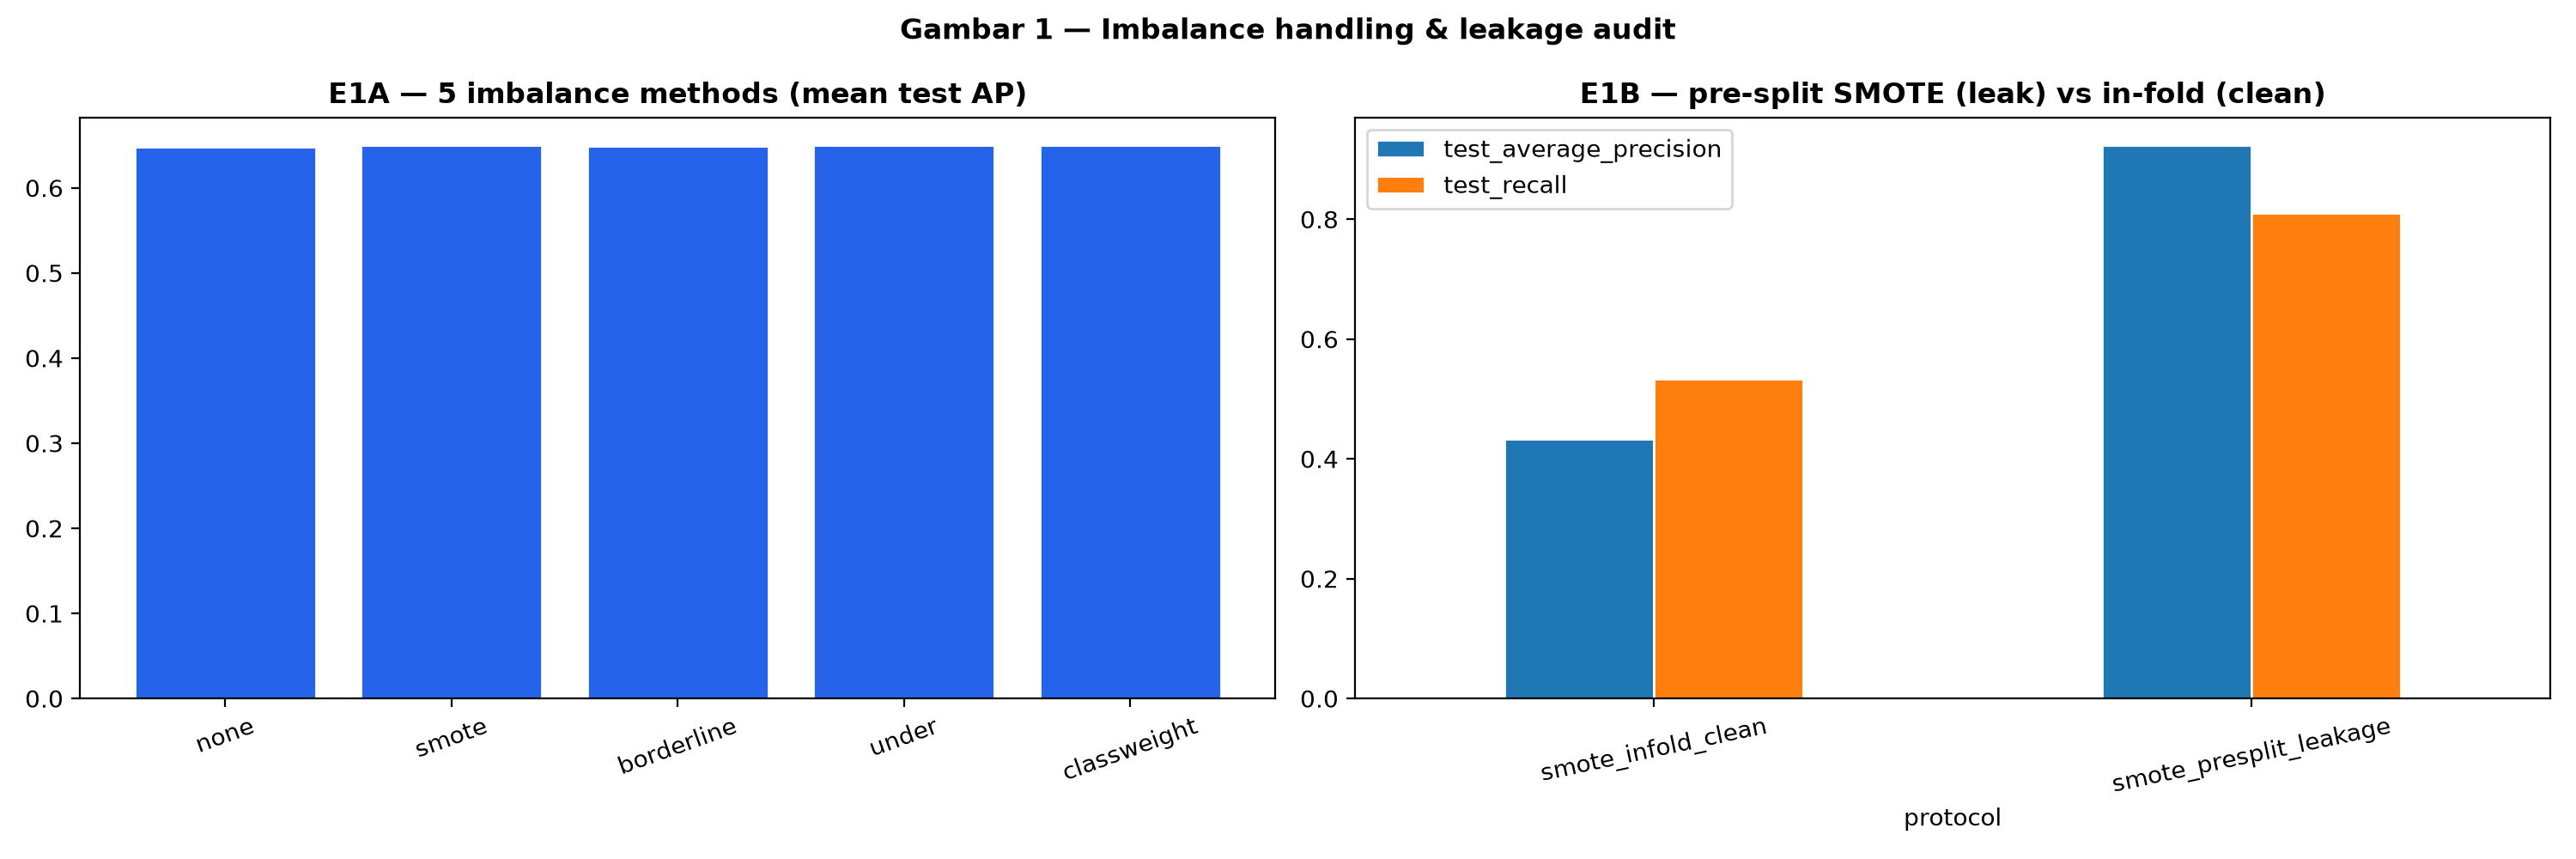

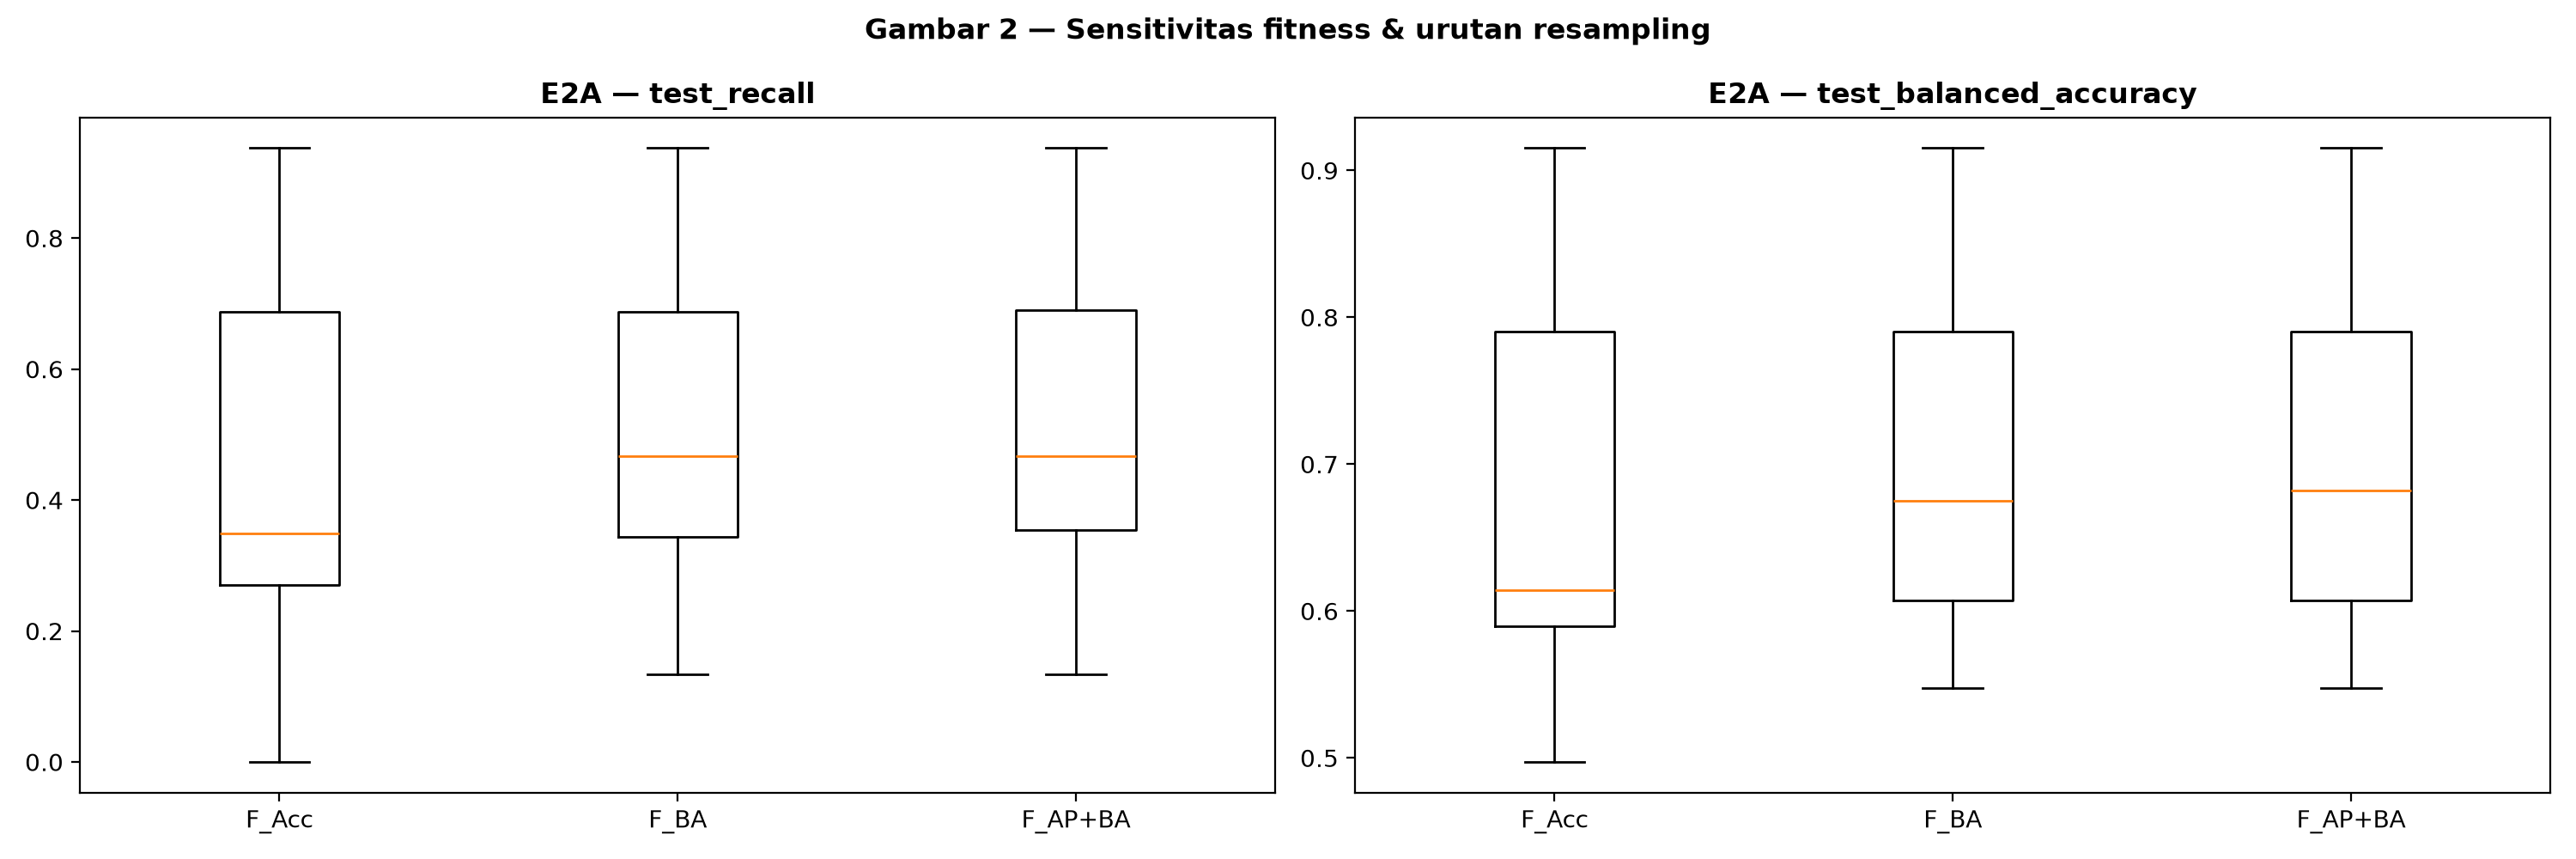

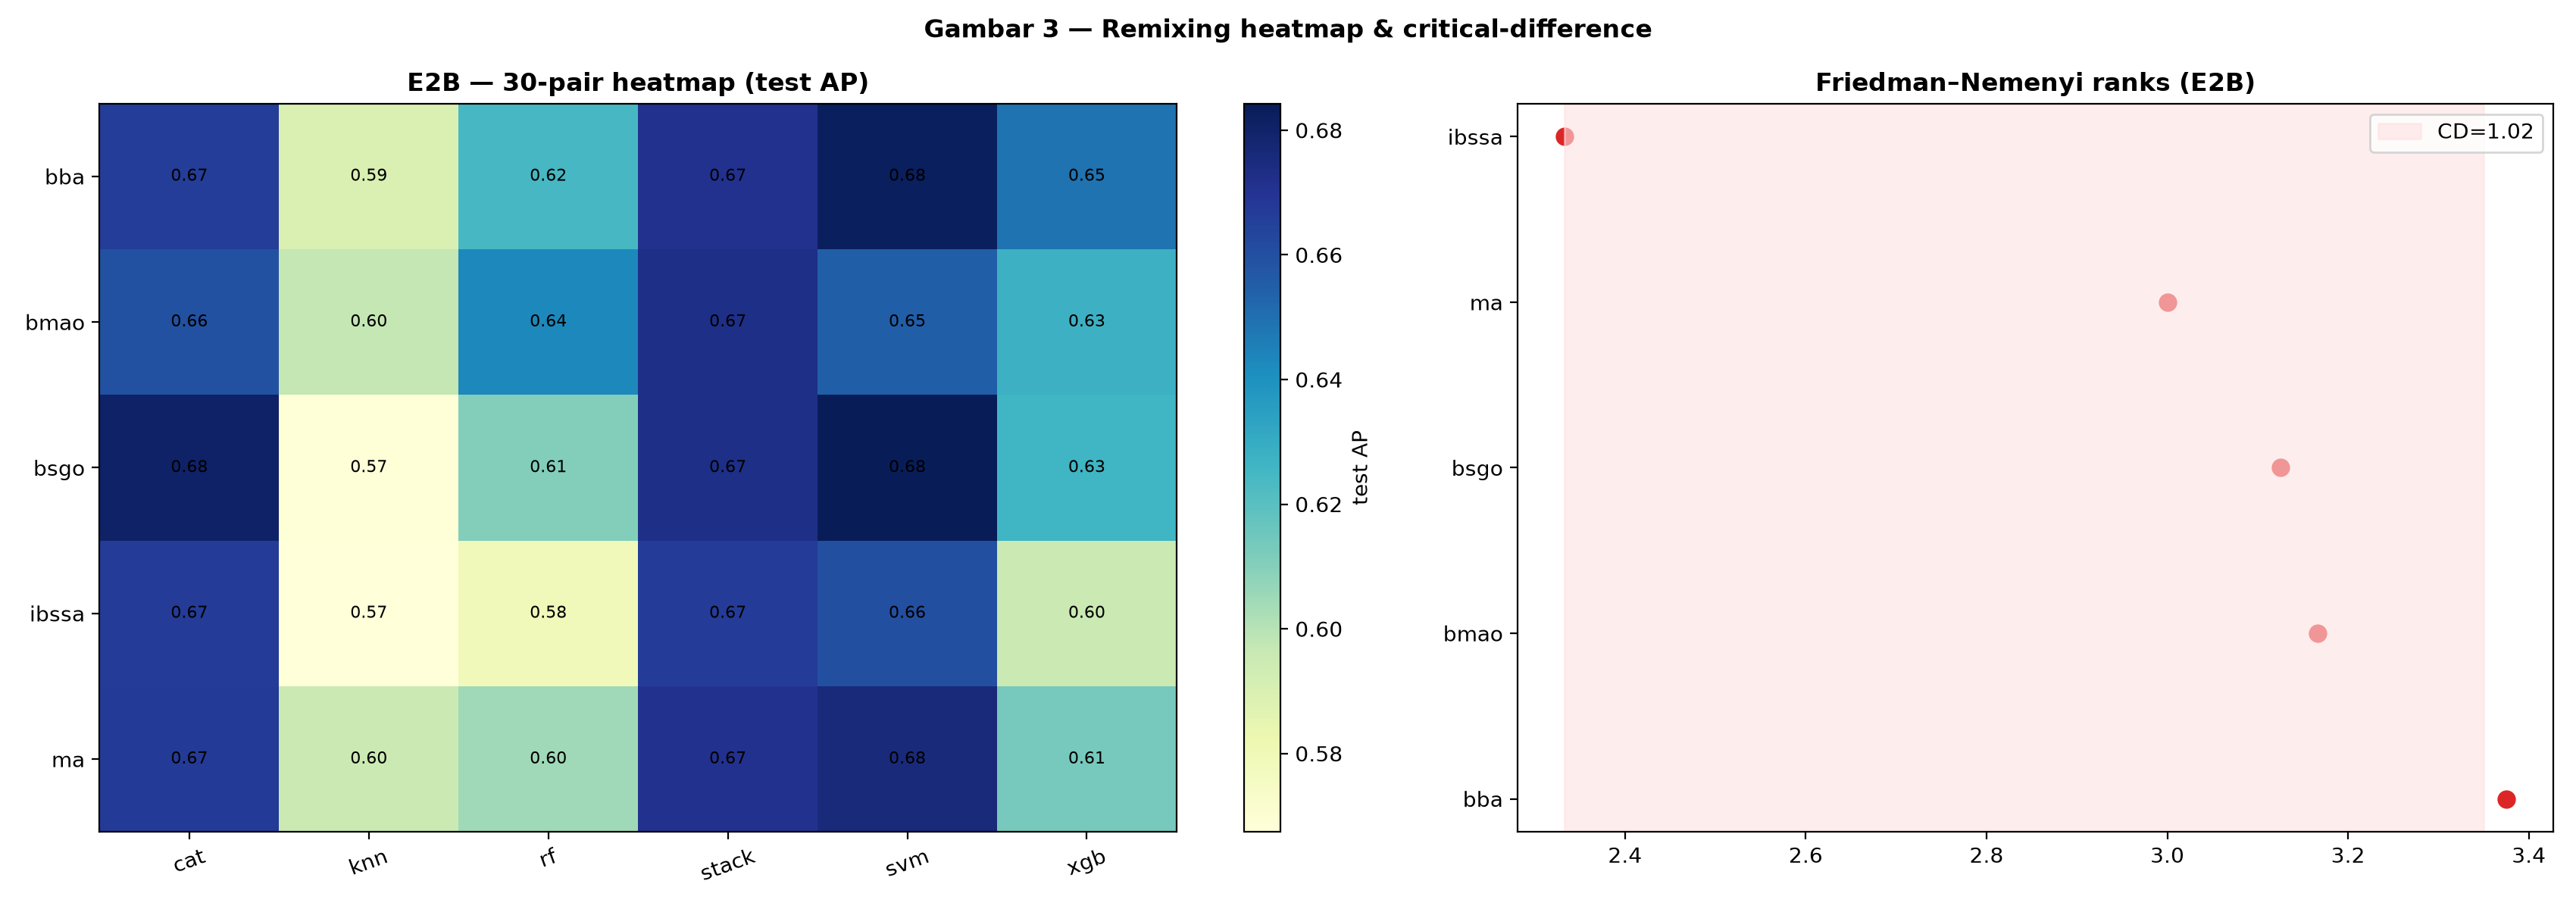

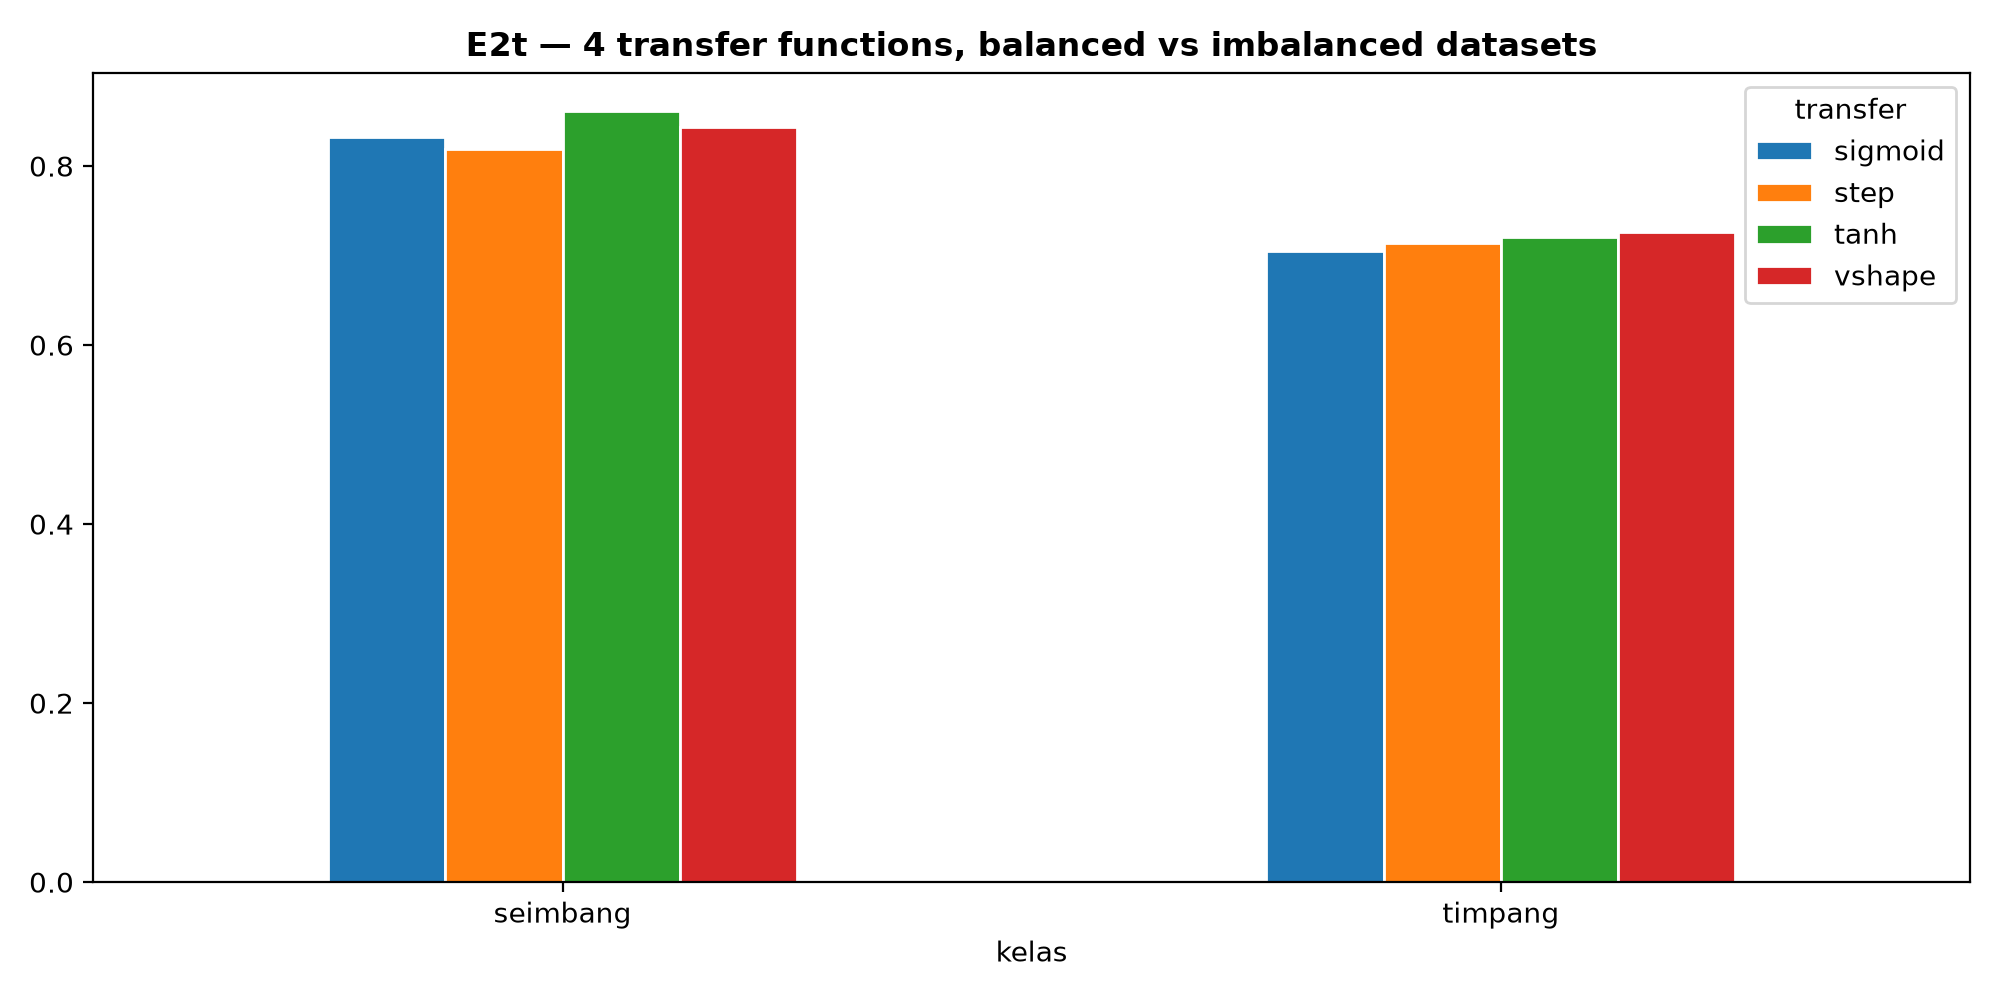

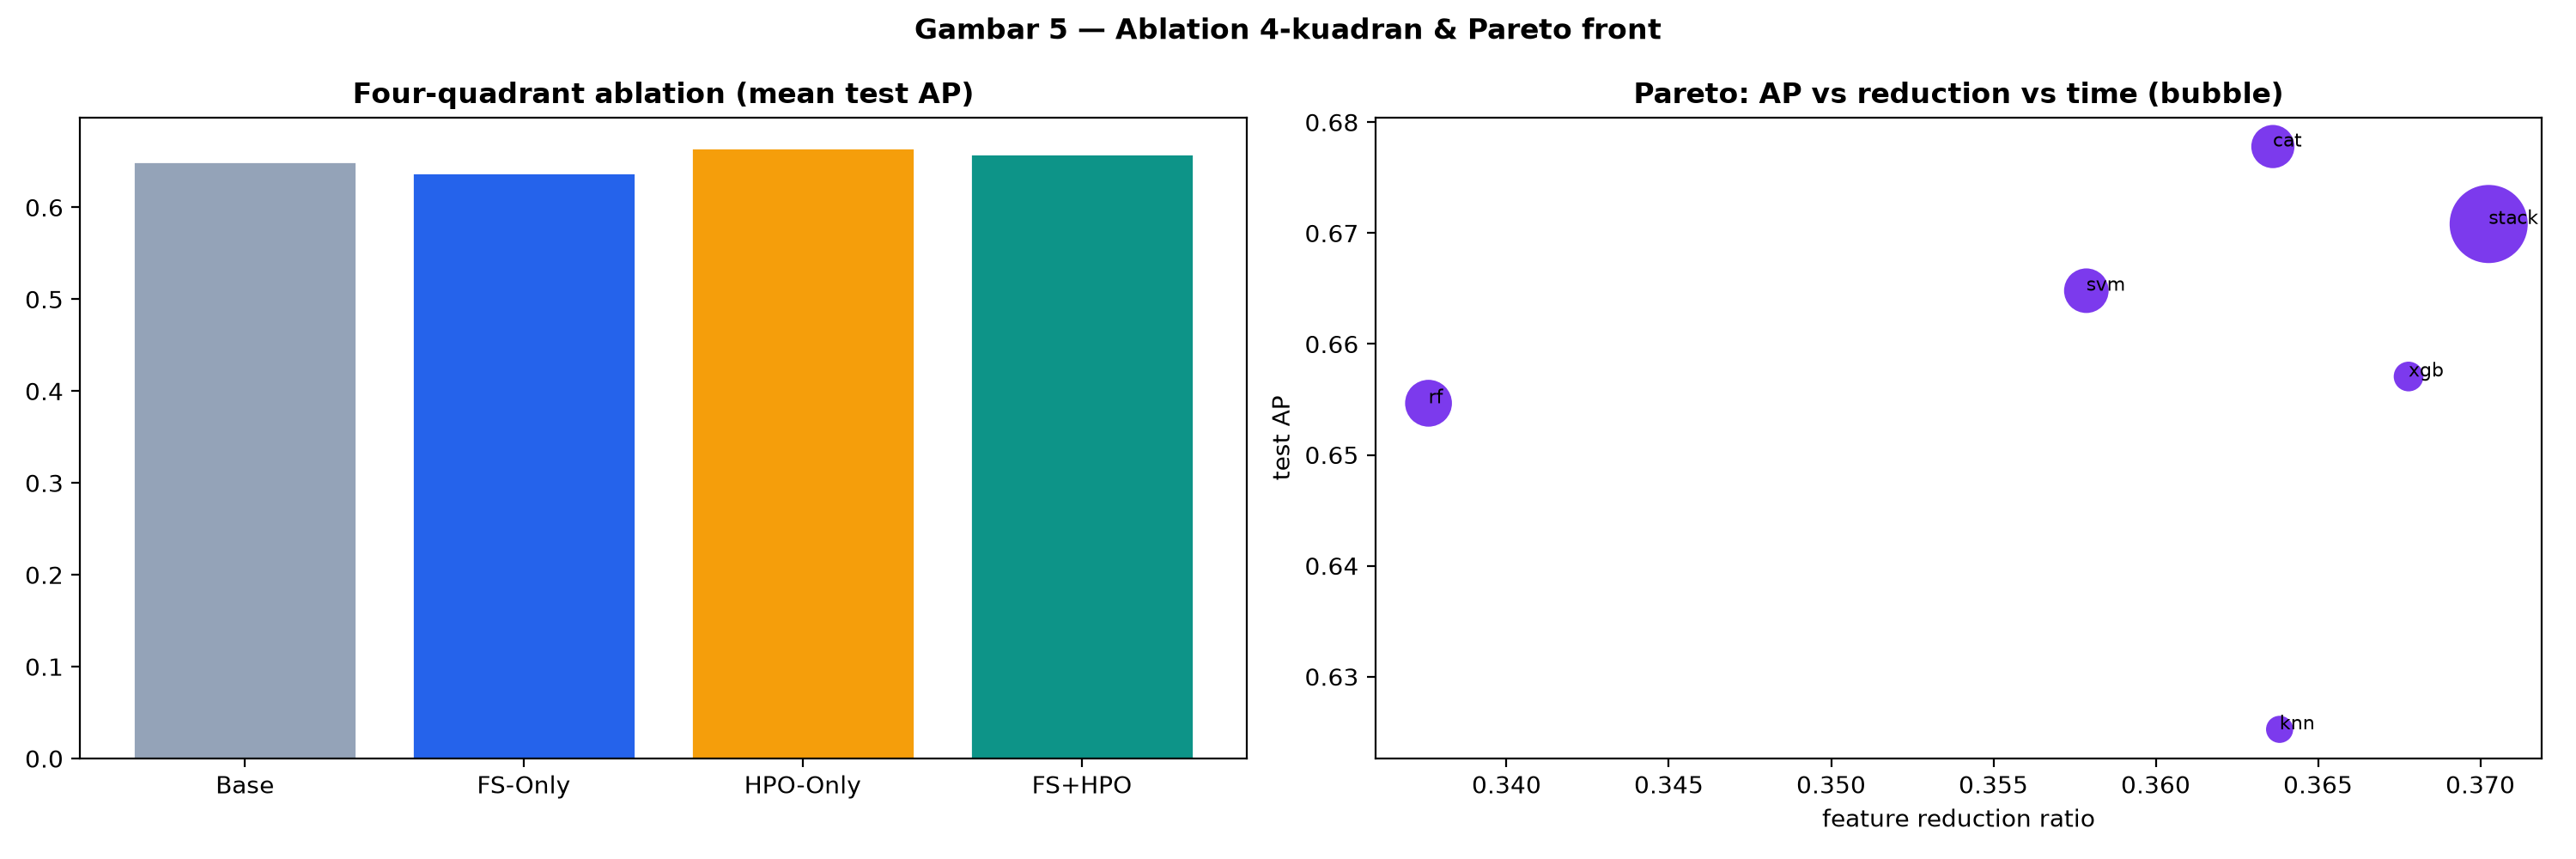

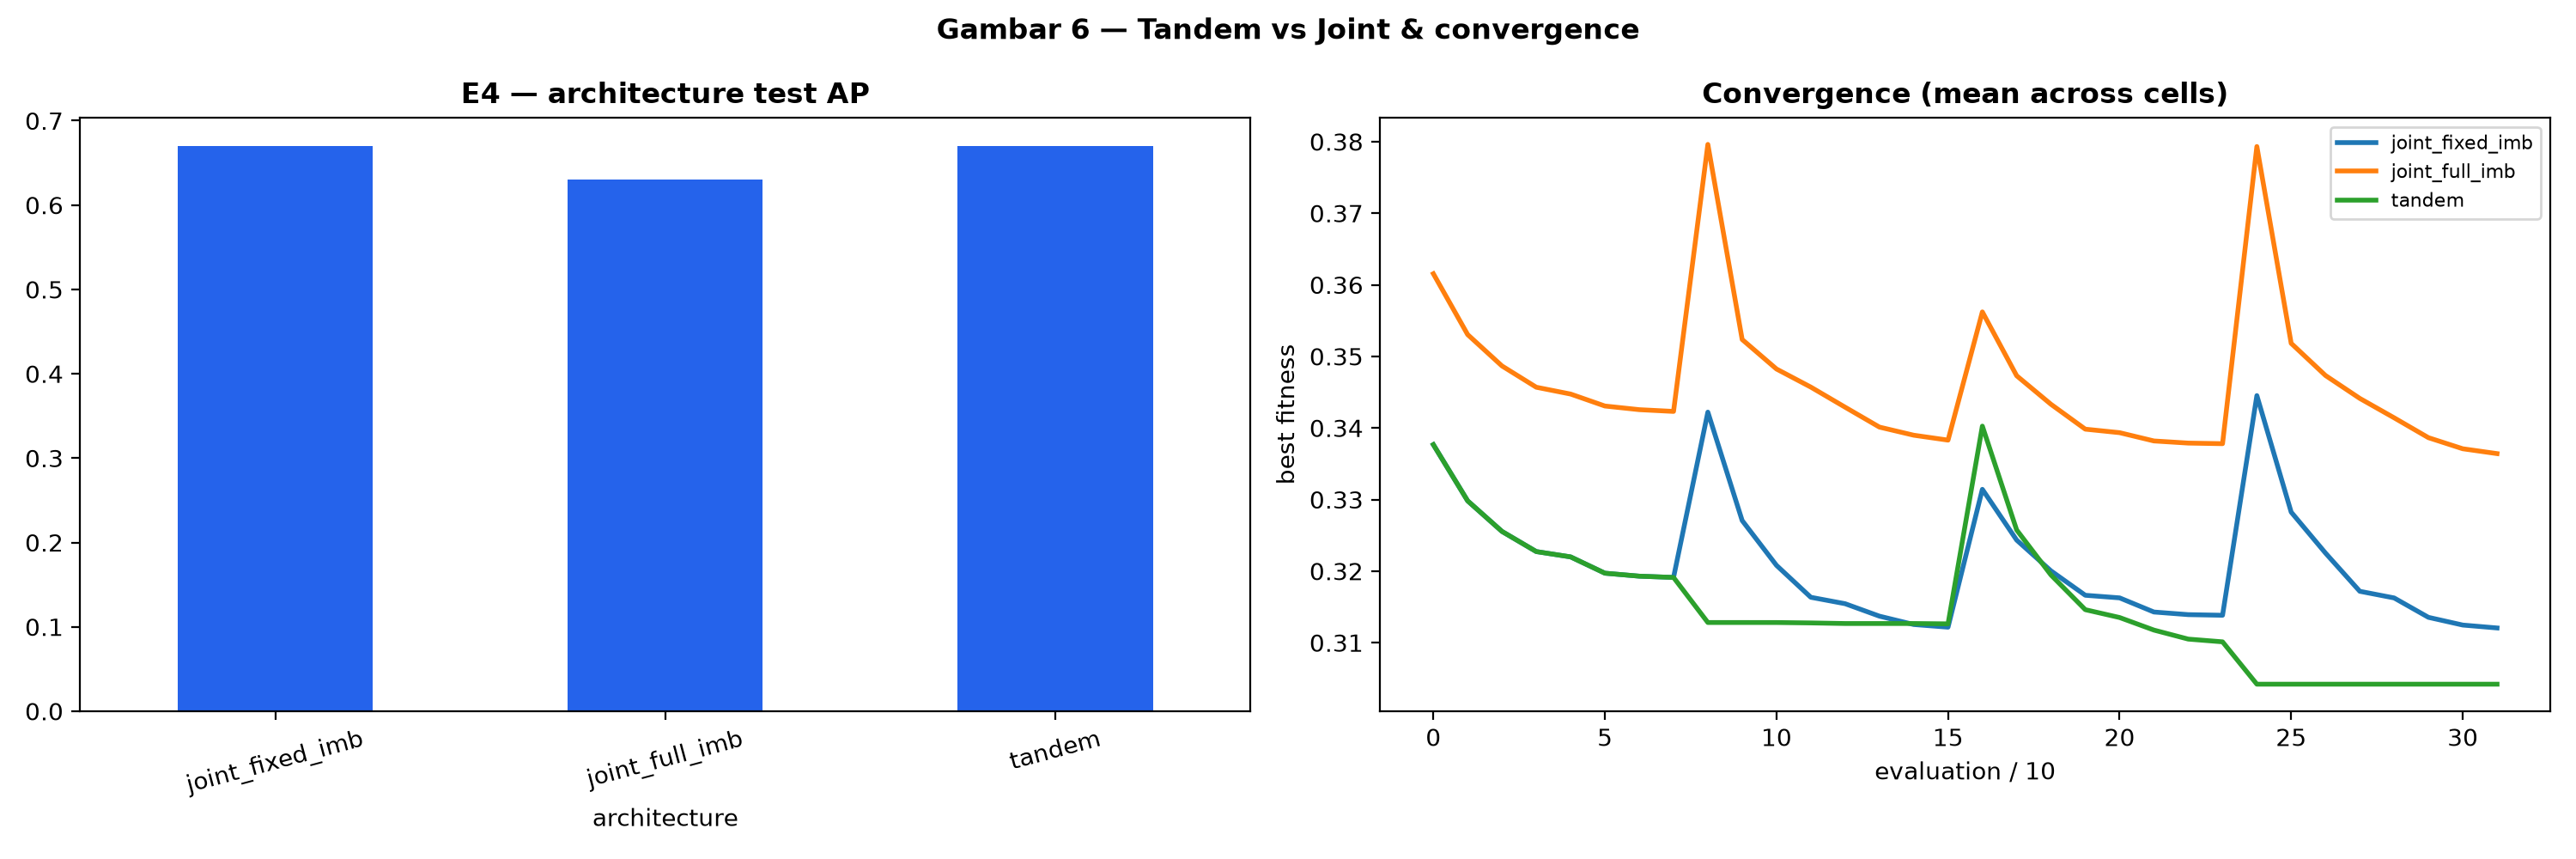

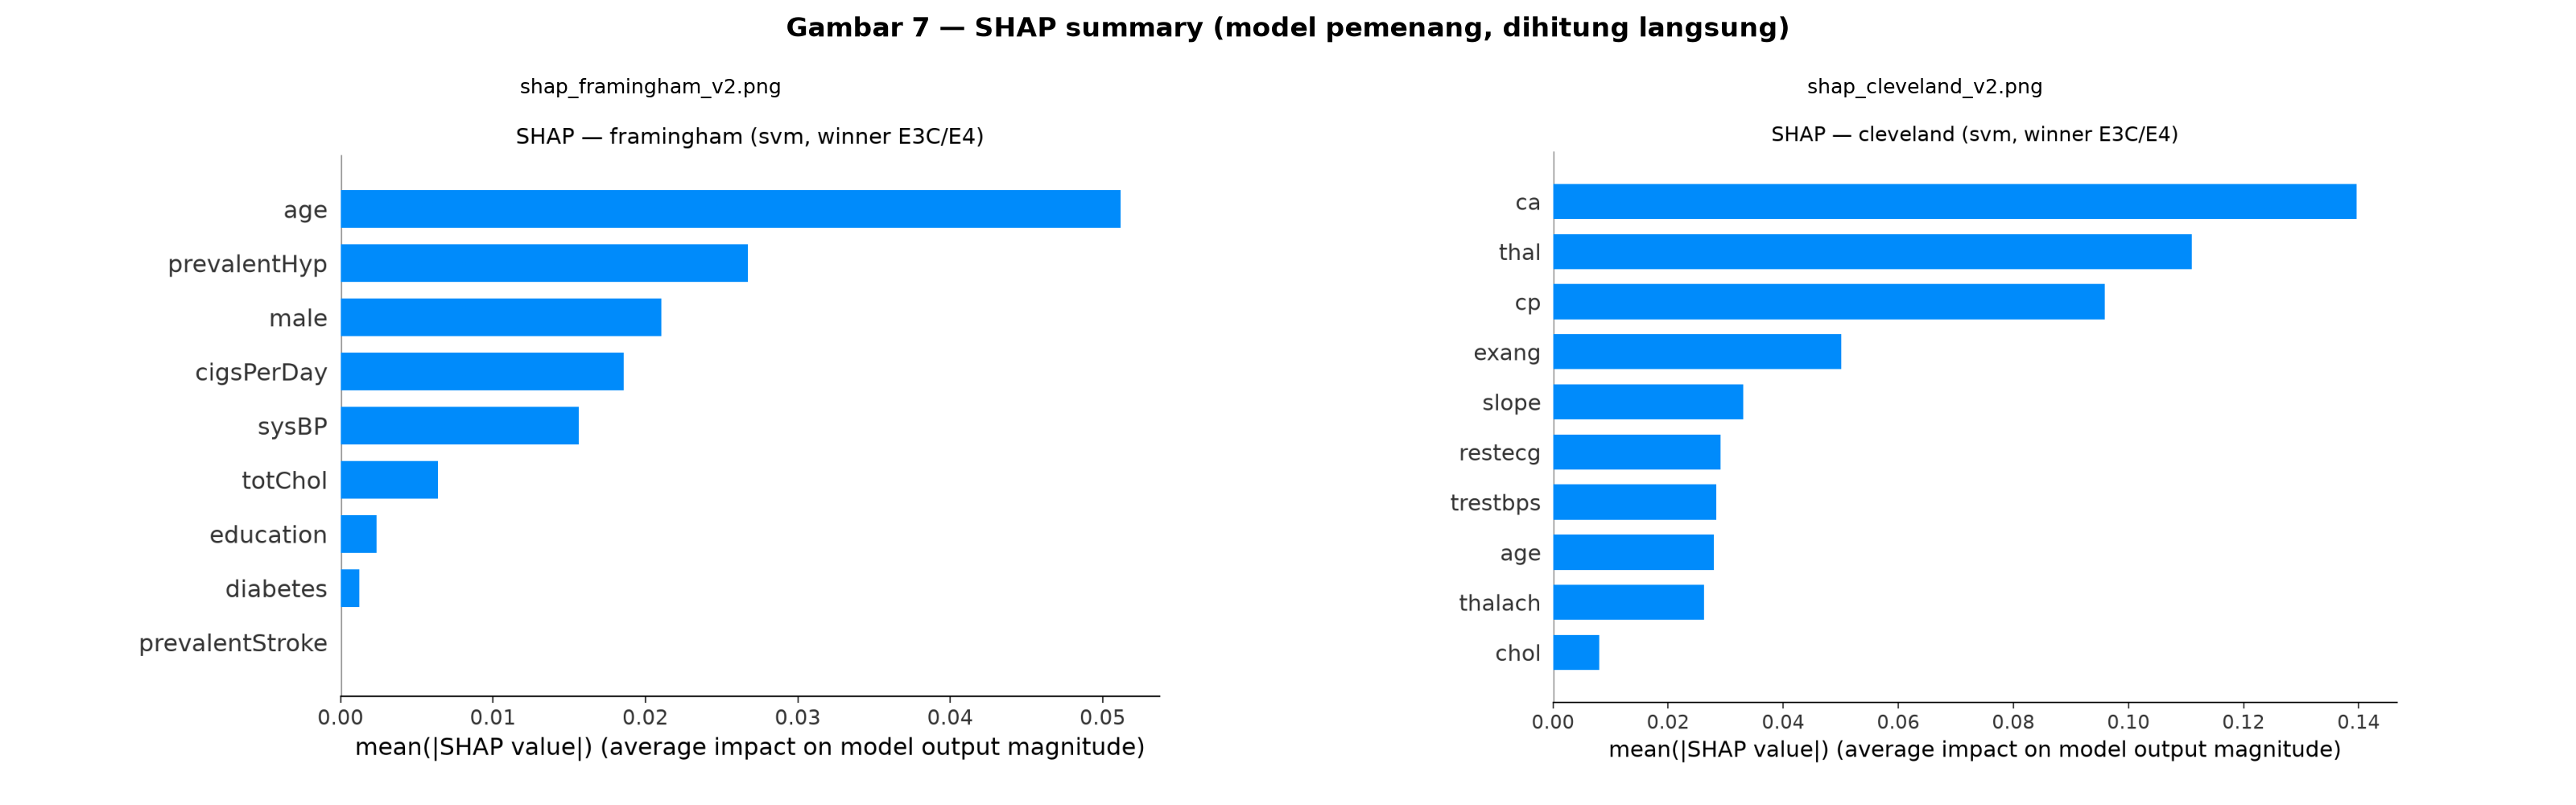

In [14]:
# ============================================================================
# 14. E5 — skala penuh + statistik + XAI + laporan
# ============================================================================
E5 = runner.stage_e5()
if E5 is not None and len(E5):
    display(E5[["dataset", "classifier", "fs_optimizer", "seed",
                "test_average_precision", "test_recall", "test_balanced_accuracy",
                "fit_seconds"]].round(4))
if PROFILE != "smoke" or (Path(core.RES2) / "rj2_exp3b_joint.csv").exists():
    runner.stage_report()
    for _f in ["fig1_imbalance_and_leakage.png", "fig2_fitness_sensitivity_ablation.png",
               "fig3_remixing_heatmap_cd.png", "fig4_transfer_balanced_vs_imbalanced.png",
               "fig5_four_quadrant_and_pareto.png", "fig6_tandem_vs_joint_convergence.png",
               "fig7_xai_shap_lime.png"]:
        _p = Path(core.FIG2) / _f
        if _p.exists() and Image is not None:
            display(Image(filename=str(_p), width=1100))
        else:
            print("[figures] tidak ditemukan:", _f)


## Verifikasi akhir (Test 5 & 6) — skema metrik & integrasi

Test 5 memeriksa seluruh 9 metrik uji tidak NaN/Inf dan berada pada rentang
valid, serta 5 metrik utama muncul di `rj2_friedman.csv` dan `rj2_pairwise.csv`.
Test 6: notebook selesai dari atas ke bawah tanpa error dan menghasilkan
`REPORT_RJ_V2.md` + 7 figure.


In [15]:
# ============================================================================
# 15. Test 5–10 — skema, statistik, integrasi, patch audit v2.1
# ============================================================================
MET = ["test_accuracy", "test_recall", "test_specificity", "test_precision",
       "test_f1", "test_roc_auc", "test_average_precision",
       "test_balanced_accuracy", "test_mcc"]
FILES = ["rj2_exp1a_imbalance.csv", "rj2_exp2b_remixing.csv",
         "rj2_exp3b_joint.csv", "rj2_exp4_tandem_joint.csv"]
schema_ok, schema_detail = True, []
for f in FILES:
    p = Path(core.RES2) / f
    if not p.exists():
        schema_detail.append(f"{f}: belum ada (dilewati)")
        continue
    d = pd.read_csv(p)
    missing = [m for m in MET if m not in d.columns]
    bad = []
    for m in MET:
        if m in d.columns:
            v = pd.to_numeric(d[m], errors="coerce")
            lo = -1.0 if m == "test_mcc" else 0.0
            if v.isna().any() or not np.isfinite(v).all() or (v < lo - 1e-9).any() \
                    or (v > 1 + 1e-9).any():
                bad.append(m)
    schema_ok &= (not missing) and (not bad)
    schema_detail.append(f"{f}: missing={missing} bad={bad}")
_check("T5 schema & metrik valid", schema_ok, " | ".join(schema_detail))

fr = Path(core.RES2) / "rj2_friedman.csv"
pw = Path(core.RES2) / "rj2_pairwise.csv"
stat_ok = fr.exists() and pw.exists()
if stat_ok:
    fd, pwd = pd.read_csv(fr), pd.read_csv(pw)
    stat_ok = all(m in set(pwd["metric"]) for m in
                  ["test_average_precision", "test_balanced_accuracy",
                   "test_recall", "test_f1", "test_mcc"])
_check("T5b 5 metrik utama di statistik", stat_ok,
       f"friedman={fr.exists()} pairwise={pw.exists()}")

rep = Path(core.RES2) / "REPORT_RJ_V2.md"
figs = list(Path(core.FIG2).glob("fig*.png"))
_check("T6 laporan & 7 figure", rep.exists() and len(figs) >= 7,
       f"report={rep.exists()} figures={len(figs)}")

# ---- T7: E2A SMOTE aktif, tanpa duplikat, urutan berbeda
e2a_df = pd.read_csv(Path(core.RES2) / "rj2_exp2a_fitness_order.csv")
e2a_no_dup = not e2a_df.duplicated(
    subset=["dataset", "classifier", "fs_optimizer", "variant", "seed"]).any()
e2a_smote = bool((e2a_df["imb_method"] == "smote").all())
t_f2s = e2a_df[e2a_df["variant"].str.endswith("fs_then_smote")
               & e2a_df["variant"].str.contains(r"\|ap_ba\|")]\
    .sort_values(["dataset", "classifier", "fs_optimizer", "seed"])
t_s2f = e2a_df[e2a_df["variant"].str.endswith("smote_then_fs")
               & e2a_df["variant"].str.contains(r"\|ap_ba\|")]\
    .sort_values(["dataset", "classifier", "fs_optimizer", "seed"])
order_diff = (len(t_f2s) > 0 and len(t_f2s) == len(t_s2f)
              and (np.abs(t_f2s["test_average_precision"].values
                          - t_s2f["test_average_precision"].values) > 1e-9).any())
_check("T7 E2A SMOTE aktif & urutan berbeda",
       e2a_no_dup and e2a_smote and order_diff,
       f"rows={len(e2a_df)} smote={e2a_smote} no_dup={e2a_no_dup} "
       f"order_diff={order_diff}")

# ---- T8: E1A memilih best_fit; Framingham cat/xgb bukan 'none'
sel_df = pd.read_csv(Path(core.RES2) / "rj2_strategy_selection.csv")
f_sub = sel_df[(sel_df["dataset"] == "framingham")
               & (sel_df["classifier"].isin(["cat", "xgb"]))]
t8_ok = (len(f_sub) == 2) and (not (f_sub["imb_method"] == "none").any())
_check("T8 E1A seleksi best_fit Framingham", t8_ok,
       f_sub[["classifier", "imb_method"]].to_dict("records"))

# ---- T9: family-wise Holm
pw_df = pd.read_csv(Path(core.RES2) / "rj2_pairwise.csv")
t9_ok = ("family" in pw_df.columns) and (pw_df["family"].nunique() >= 5)
_check("T9 pairwise family-wise Holm", t9_ok,
       f"families={pw_df['family'].nunique() if 'family' in pw_df.columns else 0}")

# ---- T10: XAI Cleveland & Framingham
p_clev = Path(core.RES2) / "shap_values_cleveland_v2.csv"
p_fram = Path(core.RES2) / "shap_values_framingham_v2.csv"
_check("T10 XAI Cleveland & Framingham", p_clev.exists() and p_fram.exists(),
       f"cleveland={p_clev.exists()} framingham={p_fram.exists()}")

FINAL = pd.DataFrame(ASSERT)
display(FINAL)
if (FINAL["status"] == "FAIL").any():
    raise AssertionError("Verifikasi akhir gagal — lihat tabel.")
print("\nSEMUA TEST (1-10) PASS.")
print(f"Laporan: {rep}")


PASS T5 schema & metrik valid :: rj2_exp1a_imbalance.csv: missing=[] bad=[] | rj2_exp2b_remixing.csv: missing=[] bad=[] | rj2_exp3b_joint.csv: missing=[] bad=[] | rj2_exp4_tandem_joint.csv: missing=[] bad=[]
PASS T5b 5 metrik utama di statistik :: friedman=True pairwise=True
PASS T6 laporan & 7 figure :: report=True figures=7
PASS T7 E2A SMOTE aktif & urutan berbeda :: rows=216 smote=True no_dup=True order_diff=True
PASS T8 E1A seleksi best_fit Framingham :: [{'classifier': 'cat', 'imb_method': 'classweight'}, {'classifier': 'xgb', 'imb_method': 'under'}]
PASS T9 pairwise family-wise Holm :: families=8
PASS T10 XAI Cleveland & Framingham :: cleveland=True framingham=True


,test,status,detail
0,T1 undersampling aktif,PASS,"neg 2517 -> 563, AP 0.3162 vs 0.2930"
1,T2a class-weight cardio ~1,PASS,0.9668654738237243
2,T2b class-weight framingham ~5.58,PASS,5.580931263858093
3,T3a FS-only n_evals=80,PASS,80
4,T3b HPO-only n_evals=160,PASS,160
5,T3c Joint n_evals=160,PASS,160
6,T3d Tandem n_evals=160,PASS,160
7,T4a resampler in-fold only,PASS,"[1666, 1667]"
8,T4b preprocessing fit train-only,PASS,fit_rows=2968 n_train=2968
9,T5 schema & metrik valid,PASS,rj2_exp1a_imbalance.csv: missing=[] bad=[] | r...



SEMUA TEST (1-10) PASS.
Laporan: D:\Plus Iso\Kuliah S2\Kecerdasan Komputasional A\Percobaan Final KK\replication\results_rj_v2\REPORT_RJ_V2.md


## Selesai — ringkasan artefak

| File | Isi |
|---|---|
| `rj2_exp1a_imbalance.csv` | E1A 900 sel (5 metode × 6 klasifier × 6 ds × 5 seed) |
| `rj2_strategy_selection.csv` | Strategi adaptif terpilih |
| `rj2_exp1b_leakage_audit.csv` | E1B 180 sel leaky vs clean |
| `rj2_exp2a_fitness_order.csv` | E2A 216 sel fitness & order |
| `rj2_exp2b_remixing.csv` | E2B 180 sel remixing |
| `rj2_exp2t_transfer.csv` | E2t 240 sel transfer |
| `rj2_exp3a_hpo_only.csv` | E3A 108 sel HPO-only |
| `rj2_exp3b_joint.csv` | E3B 180 sel joint |
| `rj2_exp3c_multiseed.csv` | E3C 180 sel multi-seed |
| `rj2_exp4_tandem_joint.csv` | E4 324 sel arsitektur |
| `rj2_exp5_cardio70k.csv` | E5 18 sel skala penuh |
| `rj2_friedman.csv`, `rj2_pairwise.csv`, `rj2_nemenyi.csv` | Statistik |
| `fig1`–`fig7` | 7 figure siap slide |
| `REPORT_RJ_V2.md` | Laporan per Tujuan 01/02/03 |

**Konfigurasi CPU:** `MFL_USE_GPU=0`, `MFL_WORKERS=12`, `MFL_THREADS=1`.
Untuk melanjutkan run yang terputus, cukup jalankan ulang notebook; setiap tahap
membaca CSV yang sudah ada dan melewati kunci `(dataset, classifier, optimizer,
variant, seed)` yang selesai.
